# Assignment Meshed AC–DC Networks
## Submitted by Muhammad Umer (05/11/2026)


In [4]:

import pypsa
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
import warnings
import logging
logging.getLogger("pypsa.optimization.optimize").setLevel(logging.WARNING)

## Task 1: Expolatory Data Analytics of meshed AC–DC network

The example has a 3-node AC network coupled via AC-DC converters to a 3-node DC network. There is also a single point-to-point DC connection using the Link component. It has six generators (three wind and three gas) and ten hourly snapshots. 

In [6]:
n = pypsa.examples.ac_dc_meshed()
n.links.loc["Norwich Converter", "p_nom_extendable"] = False

print("Snapshots:", len(n.snapshots))
print("Buses:", len(n.buses), "| Lines:", len(n.lines), "| Links:", len(n.links))
print("Loads:", len(n.loads), "| Generators:", len(n.generators))

display(n.buses[["carrier"]])
display(n.generators[["bus", "carrier", "p_nom", "p_nom_extendable",
                      "p_nom_min", "capital_cost", "marginal_cost"]])

INFO:pypsa.network.io:Imported network 'AC-DC-Meshed' has buses, carriers, generators, global_constraints, lines, links, loads


Snapshots: 10
Buses: 9 | Lines: 7 | Links: 4
Loads: 6 | Generators: 6


,carrier
name,
London,AC
Norwich,AC
Norwich DC,DC
Manchester,AC
Bremen,AC
Bremen DC,DC
Frankfurt,AC
Norway,AC
Norway DC,DC


,bus,carrier,p_nom,p_nom_extendable,p_nom_min,capital_cost,marginal_cost
name,,,,,,,
Manchester Wind,Manchester,wind,80.0,True,100.0,2793.651603,0.110000
Manchester Gas,Manchester,gas,50000.0,True,0.0,196.615168,4.532368
Norway Wind,Norway,wind,100.0,True,100.0,2184.374796,0.090000
Norway Gas,Norway,gas,20000.0,True,0.0,158.251250,5.892845
Frankfurt Wind,Frankfurt,wind,110.0,True,100.0,2129.456122,0.100000
Frankfurt Gas,Frankfurt,gas,80000.0,True,0.0,102.676953,4.086322


In [7]:
n.buses

,v_nom,type,x,y,carrier,unit,location,v_mag_pu_set,v_mag_pu_min,v_mag_pu_max,control,generator,sub_network,country
name,,,,,,,,,,,,,,
London,380.0,,-0.13,51.50,AC,,,1.0,0.0,inf,PQ,,,UK
Norwich,380.0,,1.30,52.60,AC,,,1.0,0.0,inf,PQ,,,UK
Norwich DC,200.0,,1.30,52.50,DC,,,1.0,0.0,inf,PQ,,,UK
Manchester,380.0,,-2.20,53.47,AC,,,1.0,0.0,inf,PQ,,,UK
Bremen,380.0,,8.80,53.08,AC,,,1.0,0.0,inf,PQ,,,DE
Bremen DC,200.0,,8.80,52.98,DC,,,1.0,0.0,inf,PQ,,,DE
Frankfurt,380.0,,8.70,50.12,AC,,,1.0,0.0,inf,PQ,,,DE
Norway,380.0,,10.75,60.00,AC,,,1.0,0.0,inf,PQ,,,NO
Norway DC,200.0,,10.75,60.00,DC,,,1.0,0.0,inf,PQ,,,NO


In [8]:
n.lines

,bus0,bus1,type,x,r,g,b,s_nom,s_nom_mod,s_nom_extendable,s_nom_min,s_nom_max,s_nom_set,s_max_pu,capital_cost,overnight_cost,discount_rate,fom_cost,active,build_year,lifetime,length,carrier,terrain_factor,num_parallel,v_ang_min,v_ang_max,sub_network,x_pu,r_pu,g_pu,b_pu,x_pu_eff,r_pu_eff,s_nom_opt,capital_cost_piecewise_opt
name,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,London,Manchester,,0.796878,0.000000,0.0,0.0,40000.0,0.0,True,0.0,inf,NaN,1.0,0.136716,NaN,NaN,0.0,True,0,inf,0.0,AC,1.0,1.0,-inf,inf,,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,Manchester,Norwich,,0.391560,0.000000,0.0,0.0,40000.0,0.0,True,0.0,inf,NaN,1.0,0.133492,NaN,NaN,0.0,True,0,inf,0.0,AC,1.0,1.0,-inf,inf,,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,Bremen DC,Norwich DC,,0.000000,0.212604,0.0,0.0,40000.0,0.0,True,0.0,inf,NaN,1.0,0.008673,NaN,NaN,0.0,True,0,inf,0.0,AC,1.0,1.0,-inf,inf,,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,Norwich DC,Norway DC,,0.000000,0.486164,0.0,0.0,40000.0,0.0,True,0.0,inf,NaN,1.0,0.129126,NaN,NaN,0.0,True,0,inf,0.0,AC,1.0,1.0,-inf,inf,,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Norway DC,Bremen DC,,0.000000,0.428727,0.0,0.0,40000.0,0.0,True,0.0,inf,NaN,1.0,0.062430,NaN,NaN,0.0,True,0,inf,0.0,AC,1.0,1.0,-inf,inf,,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,Norwich,London,,0.238800,0.000000,0.0,0.0,40000.0,0.0,True,0.0,inf,NaN,1.0,0.021852,NaN,NaN,0.0,True,0,inf,0.0,AC,1.0,1.0,-inf,inf,,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,Bremen,Frankfurt,,0.400000,0.000000,0.0,0.0,40000.0,0.0,True,0.0,inf,NaN,1.0,0.200000,NaN,NaN,0.0,True,0,inf,0.0,AC,1.0,1.0,-inf,inf,,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [9]:
n.generators

,bus,control,type,p_nom,p_nom_mod,p_nom_extendable,p_nom_min,p_nom_max,p_nom_set,p_min_pu,p_max_pu,p_set,p_init,e_sum_min,e_sum_max,q_set,sign,carrier,marginal_cost,marginal_cost_quadratic,active,build_year,lifetime,capital_cost,overnight_cost,discount_rate,fom_cost,efficiency,committable,maintainable,maintenance_duration,maintenance_pu,maintenance_events,start_up_cost,shut_down_cost,stand_by_cost,min_up_time,min_down_time,up_time_before,down_time_before,ramp_limit_up,ramp_limit_down,ramp_limit_start_up,ramp_limit_shut_down,weight,p_nom_opt,capital_cost_piecewise_opt
name,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Manchester Wind,Manchester,PQ,,80.0,0.0,True,100.0,inf,NaN,0.0,1.0,NaN,NaN,-inf,inf,0.0,1.0,wind,0.110000,0.0,True,0,inf,2793.651603,NaN,NaN,0.0,1.000000,False,False,0.0,1.0,1,0.0,0.0,0.0,0,0,1,0,NaN,NaN,NaN,NaN,1.0,0.0,0.0
Manchester Gas,Manchester,PQ,,50000.0,0.0,True,0.0,inf,NaN,0.0,1.0,NaN,NaN,-inf,inf,0.0,1.0,gas,4.532368,0.0,True,0,inf,196.615168,NaN,NaN,0.0,0.350026,False,False,0.0,1.0,1,0.0,0.0,0.0,0,0,1,0,NaN,NaN,NaN,NaN,1.0,0.0,0.0
Norway Wind,Norway,PQ,,100.0,0.0,True,100.0,inf,NaN,0.0,1.0,NaN,NaN,-inf,inf,0.0,1.0,wind,0.090000,0.0,True,0,inf,2184.374796,NaN,NaN,0.0,1.000000,False,False,0.0,1.0,1,0.0,0.0,0.0,0,0,1,0,NaN,NaN,NaN,NaN,1.0,0.0,0.0
Norway Gas,Norway,PQ,,20000.0,0.0,True,0.0,inf,NaN,0.0,1.0,NaN,NaN,-inf,inf,0.0,1.0,gas,5.892845,0.0,True,0,inf,158.251250,NaN,NaN,0.0,0.356836,False,False,0.0,1.0,1,0.0,0.0,0.0,0,0,1,0,NaN,NaN,NaN,NaN,1.0,0.0,0.0
Frankfurt Wind,Frankfurt,PQ,,110.0,0.0,True,100.0,inf,NaN,0.0,1.0,NaN,NaN,-inf,inf,0.0,1.0,wind,0.100000,0.0,True,0,inf,2129.456122,NaN,NaN,0.0,1.000000,False,False,0.0,1.0,1,0.0,0.0,0.0,0,0,1,0,NaN,NaN,NaN,NaN,1.0,0.0,0.0
Frankfurt Gas,Frankfurt,PQ,,80000.0,0.0,True,0.0,inf,NaN,0.0,1.0,NaN,NaN,-inf,inf,0.0,1.0,gas,4.086322,0.0,True,0,inf,102.676953,NaN,NaN,0.0,0.351666,False,False,0.0,1.0,1,0.0,0.0,0.0,0,0,1,0,NaN,NaN,NaN,NaN,1.0,0.0,0.0


{'nodes': {'Bus': <matplotlib.collections.PatchCollection at 0x15e405a0260>},
 'branches': {'Link': <matplotlib.collections.LineCollection at 0x15e40569880>,
  'Line': <matplotlib.collections.LineCollection at 0x15e406003b0>},
 'flows': {}}

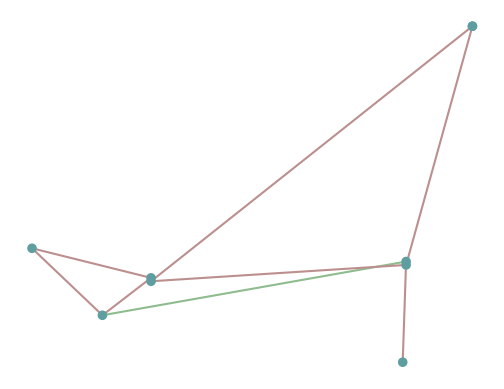

In [17]:
n.plot()

In [11]:
n.generators_t.p_max_pu

name,Manchester Wind,Frankfurt Wind,Norway Wind
snapshot,,,
2015-01-01 00:00:00,0.930020,0.559078,0.974583
2015-01-01 01:00:00,0.485748,0.752910,0.481290
2015-01-01 02:00:00,0.233692,0.123465,0.407226
2015-01-01 03:00:00,0.257604,0.966677,0.599965
2015-01-01 04:00:00,0.626906,0.859008,0.524468
2015-01-01 05:00:00,0.603598,0.526154,0.009693
2015-01-01 06:00:00,0.678908,0.077893,0.220453
2015-01-01 07:00:00,0.361303,0.059023,0.823919
2015-01-01 08:00:00,0.621604,0.248554,0.556230


In [18]:
n.optimize()
print("Objective + objective_constant:", n.objective + n.objective_constant)

capacity_results = n.generators[["bus", "carrier", "capital_cost", "marginal_cost",
                                  "p_nom_min", "p_nom_extendable"]].copy()
capacity_results["p_nom_opt_MW"] = n.generators.p_nom_opt
display(capacity_results.sort_values("p_nom_opt_MW"))

C:\Users\hp\AppData\Local\Temp\ipykernel_23824\3818081629.py:1: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  n.optimize()
Index(['2', '3', '4'], dtype='object', name='name')
Index(['0', '1', '5', '6'], dtype='object', name='name')
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.19s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 187 primals, 467 duals
Objective: -3.47e+06
Solver: highs
Runtime: 0.02s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal



Objective + objective_constant: 18440973.38746291


,bus,carrier,capital_cost,marginal_cost,p_nom_min,p_nom_extendable,p_nom_opt_MW
name,,,,,,,
Manchester Gas,Manchester,gas,196.615168,4.532368,0.0,True,0.000000
Norway Gas,Norway,gas,158.251250,5.892845,0.0,True,0.000000
Frankfurt Gas,Frankfurt,gas,102.676953,4.086322,0.0,True,982.034483
Norway Wind,Norway,wind,2184.374796,0.090000,100.0,True,1533.599858
Frankfurt Wind,Frankfurt,wind,2129.456122,0.100000,100.0,True,1667.724420
Manchester Wind,Manchester,wind,2793.651603,0.110000,100.0,True,4090.809778


## Question: Why is Frankfurt Gas dispatched at 05:00 while Manchester Gas and Norway Gas are not?
The optimization minimizes total modeled system cost while meeting load and respecting network, generator, and constraints. All buses are connected by lines with zero congestion, power can flow freely from cheap areas to expensive areas (€1593.66/ MWh at 05:00).The model's Frankfurt Gas unit has a lower marginal cost than the Manchester and Norway gas units in the supplied example (about €4.09/ MWh versus €4.53/ MWh and €5.89/MWh in the documented example data). 

In [13]:
n.generators.loc[['Frankfurt Gas', 'Norway Gas', 'Manchester Gas'], ['marginal_cost', 'p_nom', 'efficiency']]

,marginal_cost,p_nom,efficiency
name,,,
Frankfurt Gas,4.086322,80000.0,0.351666
Norway Gas,5.892845,20000.0,0.356836
Manchester Gas,4.532368,50000.0,0.350026


## Verify the exact 05:00 dispatch and binding constraints
The Gas Capacity is only utilized as a backup or peaker source, only turned on when wind cannot meet demand. However, in real time it is not possible that at installed capacity of 290 MW can optimally produce largest optimized capacity of 7292.13 MW. Moreover, the marginal price per MWh at each bus is same, which means no single constraint occurs.


In [19]:
snap = pd.Timestamp("2015-01-01 05:00:00")
print("Generator dispatch at 05:00 (MW):")
display(n.generators_t.p.loc[snap].sort_values(ascending=False).to_frame("dispatch_MW"))
print("Bus marginal prices at 05:00:")
display(n.buses_t.marginal_price.loc[snap].to_frame("price_EUR_per_MWh"))


Generator dispatch at 05:00 (MW):


,dispatch_MW
name,
Manchester Wind,2469.206273
Frankfurt Gas,982.034483
Frankfurt Wind,877.479528
Norway Wind,14.864732
Manchester Gas,-0.000000
Norway Gas,-0.000000


Bus marginal prices at 05:00:


,price_EUR_per_MWh
name,
London,1593.664974
Norwich,1593.664974
Norwich DC,1593.664974
Manchester,1593.664974
Bremen,1593.664974
Bremen DC,1593.664974
Frankfurt,1593.464974
Norway,1593.664974
Norway DC,1593.664974


In [20]:
n.statistics()

Optimal Capacity  Installed Capacity       Supply   Withdrawal  Energy Balance  Transmission  Capacity Factor  Curtailment  Capital Expenditure  Operational Expenditure       Revenue  Market Value
Generator gas          982.03448            150000.0   1465.27439      0.00000      1465.27439       0.00000         0.149208   8355.07044         1.008323e+05               5987.58295  2.285246e+06   1559.602632
          wind        7292.13406               290.0  31082.35370      0.00000     31082.35370       0.00000         0.426245   5548.78443         1.832960e+07               3193.16427  1.833279e+07    589.813548
Line      AC          5251.20513            280000.0  13775.97417  13084.62523       691.34894    -691.34894         0.511513      0.00000         6.032029e+02                  0.00000  5.223253e+05     19.445781
Link      DC          3650.57000              4000.0   8996.25483   7553.71931      1442.53552   -1442.53552         0.453353  34297.66553         9.669813e+02                  0.00000  1.172408e+06     70.840479
Load      load           0.00000                 0.0      0.00000  32547.62808    -32547.62808       0.00000              NaN      0.00000         0.000000e+00                  0.00000 -2.062011e+07   -633.536417

## Check: Generation = Demand

In [21]:
n.generators_t.p.reindex(index=n.snapshots).sum().sum()

np.float64(32547.628084104403)

In [22]:
n.loads_t.p_set.reindex(index=n.snapshots).sum().sum()

np.float64(32547.628084104403)

## Task 2: Stacked generation chart, total load, curtailment, and storage


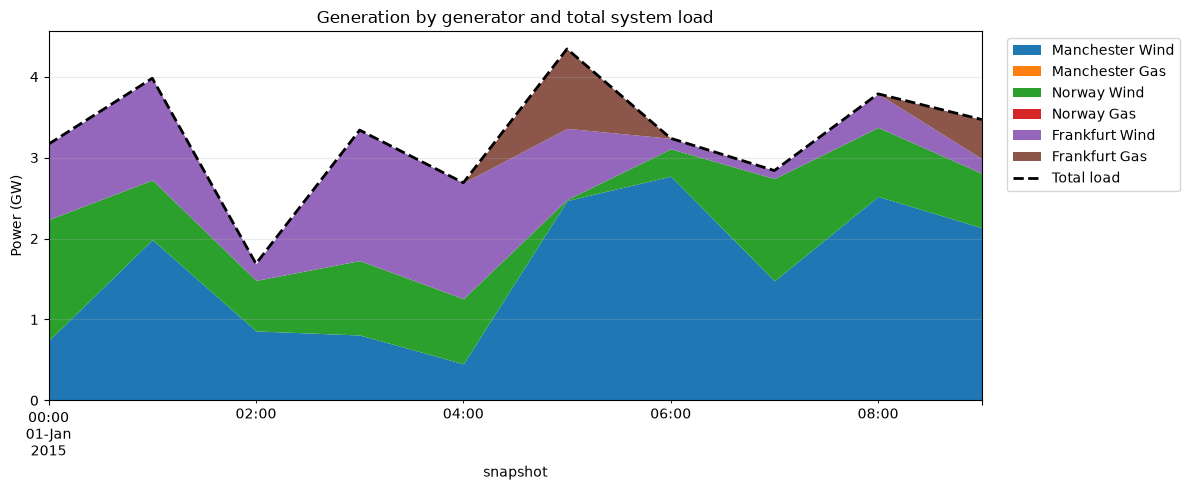

,total_load_MW,total_generation_MW,generation_minus_load_MW
snapshot,,,
2015-01-01 00:00:00,3166.980309,3166.980309,4.547474e-13
2015-01-01 01:00:00,3980.854818,3980.854818,4.547474e-13
2015-01-01 02:00:00,1688.819344,1688.819344,-2.273737e-13
2015-01-01 03:00:00,3340.069809,3340.069809,0.000000e+00
2015-01-01 04:00:00,2689.439194,2689.439194,0.000000e+00
2015-01-01 05:00:00,4343.585015,4343.585015,-9.094947e-13
2015-01-01 06:00:00,3238.845375,3238.845375,-4.547474e-13
2015-01-01 07:00:00,2840.016435,2840.016435,-9.094947e-13
2015-01-01 08:00:00,3788.242463,3788.242463,-4.547474e-13


In [23]:

gen = n.generators_t.p.reindex(index=n.snapshots) #gen net dispatch
load_by_name = n.loads_t.p_set.reindex(index=n.snapshots)
total_load = load_by_name.sum(axis=1) #net load

ax = gen.div(1e3).plot.area(figsize=(12, 5), stacked=True, linewidth=0)
(total_load / 1e3).plot(ax=ax, color="black", linestyle="--", linewidth=2,
                        label="Total load")
ax.set_ylabel("Power (GW)")
ax.set_title("Generation by generator and total system load")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
ax.grid(True, alpha=.25)
plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "total_load_MW": total_load,
    "total_generation_MW": gen.sum(axis=1),
    "generation_minus_load_MW": gen.sum(axis=1) - total_load
}))

## Question: Why does Frankfurt Gas only generate during 2 snapshots?
From the table (n.generators_t.p) for the two specific times Frankfurt Gas turns on: 05:00 (982 MW) and 09:00 (483 MW).
The actual optimized power generation from 04:00 and 06:00, the Frankfurt Gas is 0. But at 05:00, there is a sudden drop in available wind (Norway Wind drops from 804 to 14 MW, and Frankfurt Wind drops from 1432 to 877 MW), while total load goes up to 4343.58 MW. This is because wind suddenly dropped, the system needed a backup. And also the Frankfurt Gas has least marginal cost as compared to other gas generators, therefore it was turned on to prevent a blackout. 

In [24]:
n.generators_t.p

name,Manchester Wind,Manchester Gas,Norway Wind,Norway Gas,Frankfurt Wind,Frankfurt Gas
snapshot,,,,,,
2015-01-01 00:00:00,739.970940,-0.0,1494.620662,-0.0,932.388707,-0.000000
2015-01-01 01:00:00,1987.100952,-0.0,738.106855,-0.0,1255.647012,-0.000000
2015-01-01 02:00:00,858.392169,-0.0,624.521432,-0.0,205.905743,-0.000000
2015-01-01 03:00:00,807.813368,-0.0,920.106182,-0.0,1612.150259,-0.000000
2015-01-01 04:00:00,452.526516,-0.0,804.324386,-0.0,1432.588292,-0.000000
2015-01-01 05:00:00,2469.206273,-0.0,14.864732,-0.0,877.479528,982.034483
2015-01-01 06:00:00,2770.854059,-0.0,338.087245,-0.0,129.904072,-0.000000
2015-01-01 07:00:00,1478.020255,-0.0,1263.561295,-0.0,98.434885,-0.000000
2015-01-01 08:00:00,2520.688233,-0.0,853.033829,-0.0,414.520401,-0.000000


In [25]:
n.loads_t.p_set.sum(axis=1)

snapshot
2015-01-01 00:00:00    3166.980309
2015-01-01 01:00:00    3980.854818
2015-01-01 02:00:00    1688.819344
2015-01-01 03:00:00    3340.069809
2015-01-01 04:00:00    2689.439194
2015-01-01 05:00:00    4343.585015
2015-01-01 06:00:00    3238.845375
2015-01-01 07:00:00    2840.016435
2015-01-01 08:00:00    3788.242463
2015-01-01 09:00:00    3470.775320
dtype: float64

In [26]:
n.generators_t.p.T.groupby(n.generators.carrier).sum().T

carrier,gas,wind
snapshot,,
2015-01-01 00:00:00,0.000000,3166.980309
2015-01-01 01:00:00,0.000000,3980.854818
2015-01-01 02:00:00,0.000000,1688.819344
2015-01-01 03:00:00,0.000000,3340.069809
2015-01-01 04:00:00,0.000000,2689.439194
2015-01-01 05:00:00,982.034483,3361.550533
2015-01-01 06:00:00,0.000000,3238.845375
2015-01-01 07:00:00,0.000000,2840.016435
2015-01-01 08:00:00,0.000000,3788.242463


## Question: Any times where in the real world curtailment would occur and how might a storage option benefit the system?
In the real world, curtailment occurs when generation exceeds demand, or when transmission lines hit their capacity limits. In this model, we can visually see curtailment in the plot at 02:00, 06:00, and 08:00, where the stacked wind generation rises above the black dashed "Total load" line. The system is forced to discard this excess, clean wind energy. Therefore, BESS can absorb this excess wind power during low-demand periods (like 02:00) instead of wasting it.

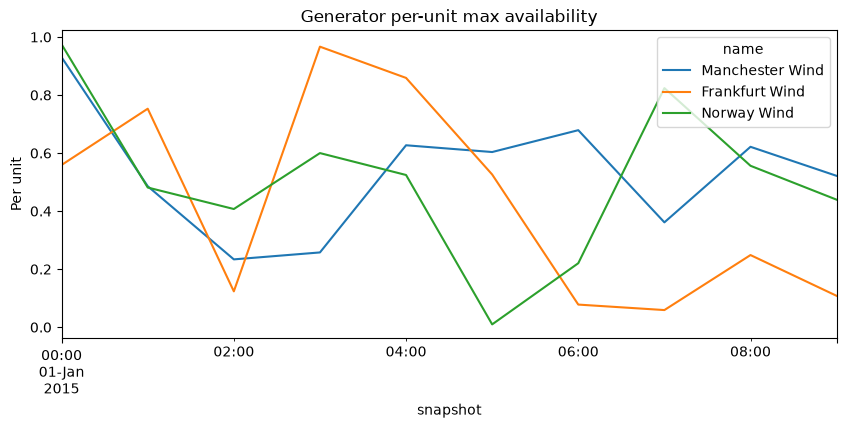

In [27]:
n.generators_t.p_max_pu.plot(figsize=(10, 4))
plt.title("Generator per-unit max availability")
plt.ylabel("Per unit")
plt.show()

#                      Task 3: Single-node network and capital-cost threshold

All generators and loads are moved to the Frankfurt bus. Norway Wind availability is set to 1.0 at every snapshot, and the minimum capacity of Manchester Wind and Frankfurt Wind is reduced to zero, as specified in the assignment. The Frankfurt Gas as of now again optimized at 
timeshots at 01:00, 05:00, 08:00.


In [34]:
n3 = pypsa.examples.ac_dc_meshed()
n3.links.loc["Norwich Converter", "p_nom_extendable"] = False
n3.generators.loc[:, "bus"] = "Frankfurt"
n3.loads.loc[:, "bus"] = "Frankfurt"
n3.generators_t.p_max_pu.loc[:, "Norway Wind"] = 1.0
n3.generators.loc[["Manchester Wind", "Frankfurt Wind"], "p_nom_min"] = 0.0

n3.remove("Line", n3.lines.index.tolist())
n3.remove("Link", n3.links.index.tolist())

display(n3.generators[["bus", "carrier", "capital_cost", "marginal_cost","p_nom_min"]])

INFO:pypsa.network.io:Imported network 'AC-DC-Meshed' has buses, carriers, generators, global_constraints, lines, links, loads


,bus,carrier,capital_cost,marginal_cost,p_nom_min
name,,,,,
Manchester Wind,Frankfurt,wind,2793.651603,0.110000,0.0
Manchester Gas,Frankfurt,gas,196.615168,4.532368,0.0
Norway Wind,Frankfurt,wind,2184.374796,0.090000,100.0
Norway Gas,Frankfurt,gas,158.251250,5.892845,0.0
Frankfurt Wind,Frankfurt,wind,2129.456122,0.100000,0.0
Frankfurt Gas,Frankfurt,gas,102.676953,4.086322,0.0


In [35]:
n3.optimize()

C:\Users\hp\AppData\Local\Temp\ipykernel_23824\1180977587.py:1: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  n3.optimize()
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.08s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 67 primals, 137 duals
Objective: -1.40e+07
Solver: highs
Runtime: 0.01s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal



('ok', 'optimal')

In [36]:
n3.statistics ().T

Generator                          Load
                                   gas           wind           load
Optimal Capacity             794.44905     3549.13597            0.0
Installed Capacity            150000.0          290.0            0.0
Supply                      1465.27439     31082.3537            0.0
Withdrawal                         0.0            0.0    32547.62808
Energy Balance              1465.27439     31082.3537   -32547.62808
Transmission                         0              0              0
Capacity Factor               0.184439       0.875772            NaN
Curtailment                 6479.21607       4409.006            0.0
Capital Expenditure        81571.60729  7752643.16092            0.0
Operational Expenditure     5987.58295     2797.41183            0.0
Revenue                  1098456.32569  7755440.57275 -8853896.89844
Market Value                749.659126     249.512654    -272.028944

In [37]:
n3.generators_t.p

name,Manchester Wind,Manchester Gas,Norway Wind,Norway Gas,Frankfurt Wind,Frankfurt Gas
snapshot,,,,,,
2015-01-01 00:00:00,-0.0,-0.0,3166.980309,-0.0,-0.0,-0.000000
2015-01-01 01:00:00,-0.0,-0.0,3549.135970,-0.0,-0.0,431.718848
2015-01-01 02:00:00,-0.0,-0.0,1688.819344,-0.0,-0.0,-0.000000
2015-01-01 03:00:00,-0.0,-0.0,3340.069809,-0.0,-0.0,-0.000000
2015-01-01 04:00:00,-0.0,-0.0,2689.439194,-0.0,-0.0,-0.000000
2015-01-01 05:00:00,-0.0,-0.0,3549.135970,-0.0,-0.0,794.449045
2015-01-01 06:00:00,-0.0,-0.0,3238.845375,-0.0,-0.0,-0.000000
2015-01-01 07:00:00,-0.0,-0.0,2840.016435,-0.0,-0.0,-0.000000
2015-01-01 08:00:00,-0.0,-0.0,3549.135970,-0.0,-0.0,239.106493


In [38]:
float (n3.generators.loc["Norway Wind", "capital_cost"])

2184.3747960912

## Determination of capital cost the optimization will begin replacing the “Frankfurt Gas” generator with more “Norway Wind”.
In this step, at first the reference CAPEX is determined for Norway Wind. Next a loop is designed by scaling down the capital cost from 2200 to 0, from which we can observe the exact threshold. The iteration and optimization result shows that at cost 110, Frankfurt Gas drops to 362.73 MW and At cost 55, Frankfurt Gas drops to 0.0 MW, and Norway Wind capacity jumps up. 

In [42]:
def run_single_bus(wind_capital_cost):
    m = pypsa.examples.ac_dc_meshed()
    m.generators.loc[:, "bus"] = "Frankfurt"
    m.loads.loc[:, "bus"] = "Frankfurt"
    m.generators_t.p_max_pu.loc[:, "Norway Wind"] = 1.0
    m.generators.loc[["Manchester Wind", "Frankfurt Wind"], "p_nom_min"] = 0.0
    m.generators.loc["Norway Wind", "capital_cost"] = float(wind_capital_cost)
    m.remove("Line", m.lines.index.tolist())
    m.remove("Link", m.links.index.tolist())
    m.optimize()
    return m
    
reference_cost = float(n3.generators.loc["Norway Wind", "capital_cost"])
m_reference = run_single_bus(reference_cost)
print("Reference Norway Wind capital cost:", reference_cost)
display(m_reference.generators[["capital_cost", "marginal_cost", "p_nom_min", "p_nom_opt"]])



INFO:pypsa.network.io:Imported network 'AC-DC-Meshed' has buses, carriers, generators, global_constraints, lines, links, loads
C:\Users\hp\AppData\Local\Temp\ipykernel_23824\2970593066.py:10: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  m.optimize()
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.07s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 67 primals, 137 duals
Objective: -1.40e+07
Solver: highs
Runtime: 0.00s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal



Reference Norway Wind capital cost: 2184.3747960912


,capital_cost,marginal_cost,p_nom_min,p_nom_opt
name,,,,
Manchester Wind,2793.651603,0.110000,0.0,0.000000
Manchester Gas,196.615168,4.532368,0.0,0.000000
Norway Wind,2184.374796,0.090000,100.0,3549.135970
Norway Gas,158.251250,5.892845,0.0,0.000000
Frankfurt Wind,2129.456122,0.100000,0.0,0.000000
Frankfurt Gas,102.676953,4.086322,0.0,794.449045


In [44]:
def mcost(cost):
    m = run_single_bus(cost)
    return {
        "Norway_Wind_capital_cost": cost,
        "Norway_Wind_p_nom_opt_MW": m.generators.at["Norway Wind", "p_nom_opt"],
        "Frankfurt_Gas_p_nom_opt_MW": m.generators.at["Frankfurt Gas", "p_nom_opt"],
        "objective_plus_constant": m.objective + m.objective_constant,
    }
cost_grid = np.linspace(2200, 0, 41)
Iterate = pd.DataFrame([mcost(c) for c in cost_grid])
display(Iterate)

INFO:pypsa.network.io:Imported network 'AC-DC-Meshed' has buses, carriers, generators, global_constraints, lines, links, loads
C:\Users\hp\AppData\Local\Temp\ipykernel_23824\2970593066.py:10: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  m.optimize()
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.07s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 67 primals, 137 duals
Objective: -1.40e+07
Solver: highs
Runtime: 0.01s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.network.io:Imported network 'AC-DC-Meshed' has buses, carriers, generators, global_constraints, lines, links, loads
C:\Users\hp\AppData\Local\Temp\ipykern

,Norway_Wind_capital_cost,Norway_Wind_p_nom_opt_MW,Frankfurt_Gas_p_nom_opt_MW,objective_plus_constant
0,2200.0,3549.135970,794.449045,7.898456e+06
1,2145.0,3549.135970,794.449045,7.703253e+06
2,2090.0,3549.135970,794.449045,7.508051e+06
3,2035.0,3549.135970,794.449045,7.312848e+06
4,1980.0,3549.135970,794.449045,7.117646e+06
5,1925.0,3549.135970,794.449045,6.922443e+06
6,1870.0,3549.135970,794.449045,6.727241e+06
7,1815.0,3549.135970,794.449045,6.532038e+06
8,1760.0,3549.135970,794.449045,6.336836e+06
9,1705.0,3549.135970,794.449045,6.141633e+06
